# Flutuações de um Vácuo Quântico

* PET Física - UFRN
* Petiano: Wallysson Pereira da Silva
* Data: 01/05/2026 

$\quad$ Neste projeto, exploraremos um dos resultados mais profundos da Teoria Quântica de Campos (QFT) para simular computacionalmente o comportamento do vácuo. Rompendo com a intuição clássica de um espaço perfeitamente vazio e inerte, a física moderna nos revela que o vácuo é, na verdade, um mar dinâmico e fervilhante de energia. Através de métodos numéricos, daremos vida às flutuações de ponto zero que permeiam o estado fundamental do universo, traduzindo abstrações matemáticas da mecânica quântica e da relatividade em visualizações gráficas. Tendo isso em vista, este `Notebook` foi estruturado nas seguintes seções:

    1. Introdução Teórica;
    2. Visualização estática;
    3. Evolução temporal;
    4. Função de Correlação;
    5. Evolução Simultânea;
    6. Conclusão.

## Pré-requisitos

$\quad$ Para um melhor aproveitamento da construção lógica e do código desenvolvido ao longo deste estudo, é recomendado que o leitor possua familiaridade prévia com algumas noções fundamentais da física e matemática. Na física, são úteis as noções de Mecânica Quântica (como o Princípio da Incerteza) e de Relatividade Especial (especificamente a relação de dispersão da energia). No campo da matemática, a compreensão da álgebra de números complexos, da estatística básica e do conceito de Transformada de Fourier — essencial para a passagem matemática entre o espaço dos momentos e o espaço físico — facilitará bastante a leitura. Por fim, no aspecto computacional, assume-se um conhecimento prático em programação Python, com foco na manipulação de matrizes utilizando a biblioteca `NumPy` e na geração de gráficos com o `Matplotlib`. 

## Importando bibliotecas

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma, zeta
import mpmath

## Informações sobre as bibliotecas

In [2]:
%load_ext version_information
%version_information Matplotlib, Numpy

Software versions
Python 3.13.0 64bit [MSC v.1941 64 bit (AMD64)]
IPython 8.29.0
OS Windows 11 10.0.26200 SP0
Matplotlib 3.9.2
Numpy 2.1.3
Mon May 04 23:36:51 2026 Hora Padrão de Buenos Aires

## 1. Introdução

### 1.1 A Função Gama

A Função Gama, denotada por $\Gamma(z)$, é uma das funções especiais mais importantes da matemática. Ela nasceu do desejo de interpolar a operação de fatorial para números não inteiros. Para números complexos com parte real positiva, ela é definida pela integral de Euler:$$\Gamma(z) = \int_0^\infty t^{z-1} e^{-t} dt$$A propriedade mágica dessa integral é que $\Gamma(z+1) = z\Gamma(z)$. Para qualquer número inteiro positivo $n$, isso se reduz a $\Gamma(n) = (n-1)!$. Vamos visualizar como essa função se comporta no eixo real estendido.


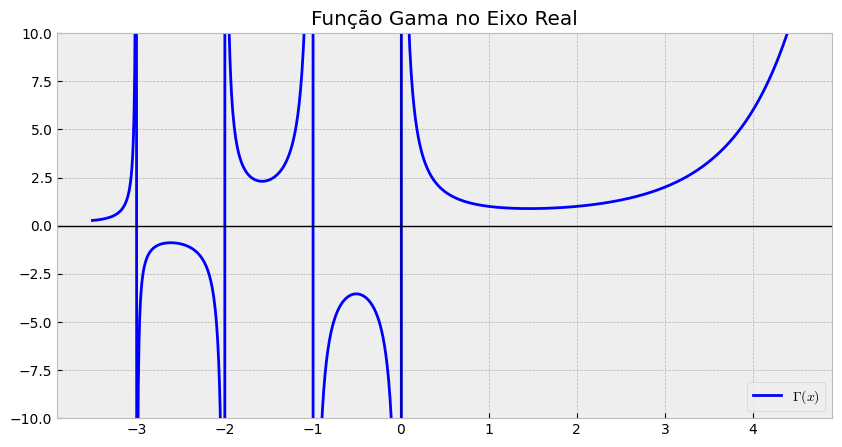

In [11]:
# Configurações de plotagem
plt.style.use('bmh')
%matplotlib inline

def plot_gamma_real():
    x = np.linspace(-3.5, 4.5, 1000)
    y = gamma(x)
    
    plt.figure(figsize=(10, 5))
    plt.plot(x, y, 'b', label=r'$\Gamma(x)$')
    plt.axhline(0, color='black', lw=1)
    plt.axvline(0, color='black', lw=1)
    plt.ylim(-10, 10)
    plt.title("Função Gama no Eixo Real")
    plt.grid(True)
    plt.legend()
    plt.show()

plot_gamma_real()

### 1.2 A Função Zeta de Riemann

A Função Zeta de Riemann, $\zeta(s)$, tem raízes na teoria dos números. Para números complexos $s$ com parte real estritamente maior que 1, ela é definida de forma simples como uma série infinita:$$\zeta(s) = \sum_{n=1}^\infty \frac{1}{n^s}$$Embora pareça simples, o verdadeiro poder da função Zeta surge através do Prolongamento Analítico, uma técnica que permite estender sua definição para todo o plano complexo (exceto no polo $s=1$). É essa extensão que nos permite avaliar a função em valores negativos e que dá origem à famosa Hipótese de Riemann.

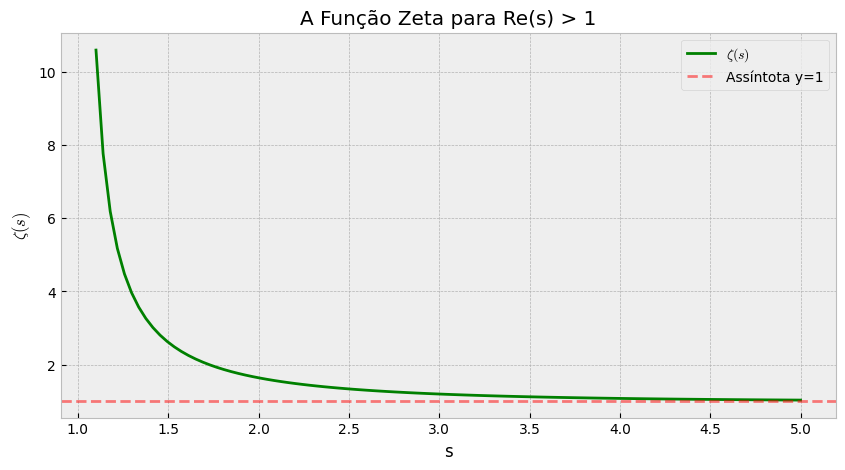

In [12]:
def plot_zeta_real():
    # Avaliando zeta para valores reais > 1
    s_vals = np.linspace(1.1, 5, 100)
    zeta_vals = [float(mpmath.zeta(s)) for s in s_vals]

    plt.figure(figsize=(10, 5))
    plt.plot(s_vals, zeta_vals, 'g', lw=2, label=r'$\zeta(s)$')
    plt.axhline(1, color='red', linestyle='--', alpha=0.5, label='Assíntota y=1')
    plt.title("A Função Zeta para Re(s) > 1")
    plt.xlabel("s")
    plt.ylabel(r"$\zeta(s)$")
    plt.grid(True)
    plt.legend()
    plt.show()

plot_zeta_real()

### 1.3 O Produto $\Gamma(s)\zeta(s)$

Agora que conhecemos a natureza contínua da Função Gama e a natureza discreta (somas de séries) da Função Zeta, podemos conectá-las. Utilizando uma transformação integral (conhecida como Transformada de Mellin), podemos multiplicar ambas e chegar a uma identidade belíssima e extremamente útil:$$\zeta(s)\Gamma(s) = \int_0^\infty \frac{x^{s-1}}{e^x - 1} dx$$Esta não é apenas uma identidade matemática curiosa. O termo no denominador, $e^x - 1$, é a exata assinatura estatística de bósons, partículas como os fótons. É através dessa integral que a matemática pura destas duas funções se torna a linguagem necessária para descrever a radiação térmica do universo, o que nos leva à nossa próxima etapa: a Física Estatística.

## 2. Visualizando a Função Zeta e a Linha Crítica

A Função Zeta é definida inicialmente como uma série convergente para $Re(s) > 1$. No entanto, através do Prolongamento Analítico, podemos estendê-la para quase todo o plano complexo. A Hipótese de Riemann sugere que todos os seus zeros não-triviais estão na "linha crítica" $s = 1/2 + it$. Vamos programar uma busca visual por esses zeros.

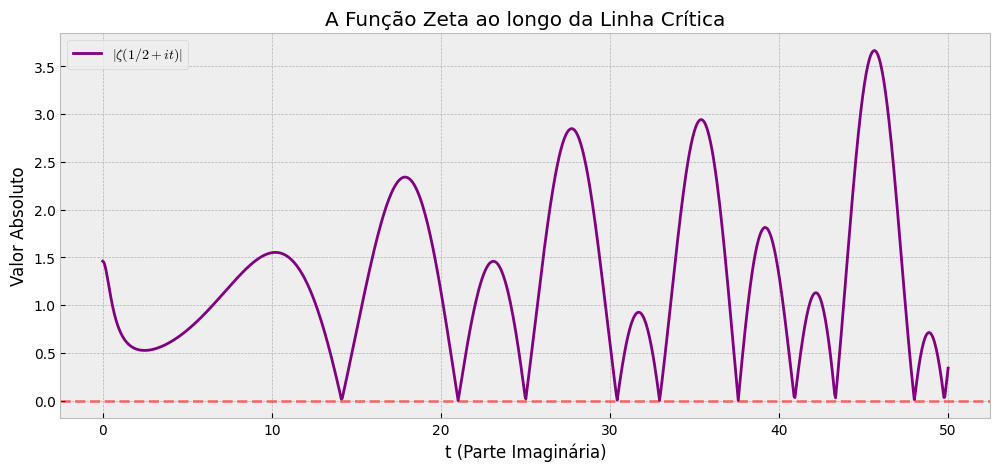

In [7]:
def plot_zeta_critical_line(t_max=50):
    t = np.linspace(0, t_max, 1000)
    # Avaliando zeta na linha crítica s = 0.5 + it
    z_values = [complex(mpmath.zeta(0.5 + 1j*val)) for val in t]
    abs_z = np.abs(z_values)

    plt.figure(figsize=(12, 5))
    plt.plot(t, abs_z, color='purple', label=r'$|\zeta(1/2 + it)|$')
    plt.axhline(0, color='red', linestyle='--', alpha=0.5)
    plt.title("A Função Zeta ao longo da Linha Crítica")
    plt.xlabel("t (Parte Imaginária)")
    plt.ylabel("Valor Absoluto")
    plt.legend()
    plt.show()

plot_zeta_critical_line(50)

## 3. Física Estatística e a Lei de Stefan-Boltzmann

Por que um físico deveria se importar com $\zeta(4)$? A resposta está na radiação de corpo negro. A integral da densidade de energia de Planck depende da integral de Bose-Einstein. Usando a identidade de Mellin (mostrada na Intro), provaremos que a energia total irradiada é proporcional a $\Gamma(4)\zeta(4)$, o que resulta na famosa constante da Lei de Stefan-Boltzmann.

In [8]:
from scipy.integrate import quad

# Integral numérica da função de Planck (adimensional)
func_planck = lambda x: x**3 / (np.exp(x) - 1)
integral_num, _ = quad(func_planck, 0, 100)

# Resultado analítico via Gama e Zeta
resultado_analitico = gamma(4) * zeta(4)

print(f"Resultado Numérico: {integral_num:.8f}")
print(f"Resultado Analítico (Gamma(4)*Zeta(4)): {resultado_analitico:.8f}")
print(f"Erro relativo: {abs(integral_num - resultado_analitico):.2e}")

Resultado Numérico: 6.49393940
Resultado Analítico (Gamma(4)*Zeta(4)): 6.49393940
Erro relativo: 7.99e-15


## 4. O "Milagre" de $\zeta(-1)$ e o Efeito Casimir

Aqui exploramos a área mais instigante: a Regularização da Função Zeta. Na física clássica, a soma $1+2+3+...$ diverge para o infinito. Na Teoria Quântica de Campos, ao calcularmos a energia do vácuo entre duas placas condutoras (Efeito Casimir), essa soma aparece. O prolongamento analítico nos diz que $\zeta(-1) = -1/12$. Vamos investigar o comportamento da função ao redor desse ponto.

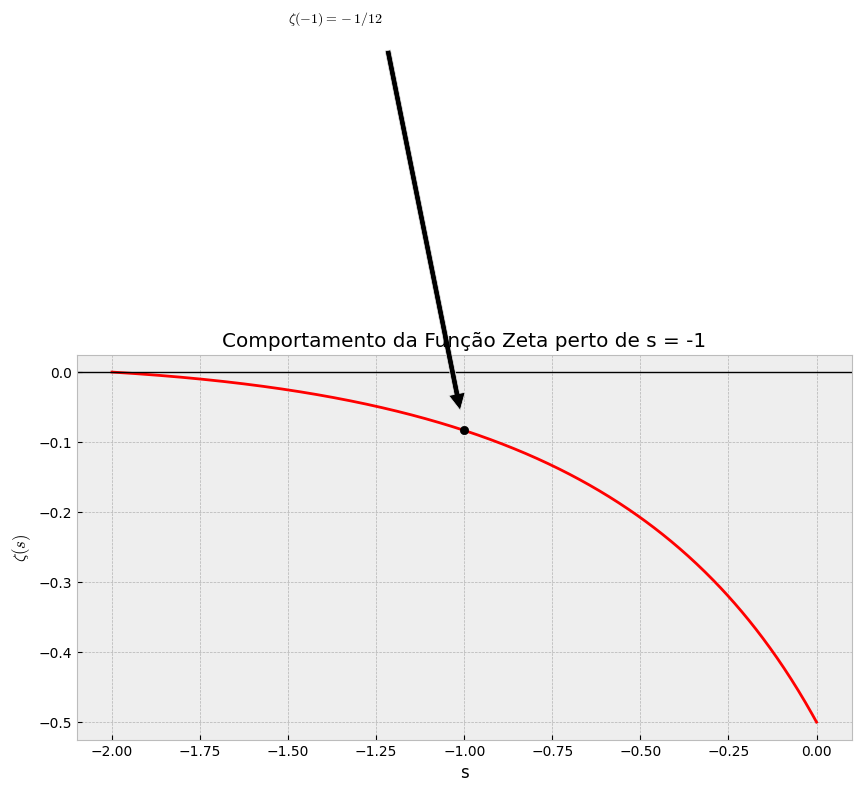

In [9]:
def explorar_zeta_negativo():
    s_vals = np.linspace(-2, 0, 500)
    zeta_vals = [float(mpmath.zeta(s)) for s in s_vals]

    plt.figure(figsize=(10, 5))
    plt.plot(s_vals, zeta_vals, 'r-', lw=2, label=r'$\zeta(s)$')
    plt.scatter([-1], [-1/12], color='black', zorder=5)
    plt.annotate(r'$\zeta(-1) = -1/12$', xy=(-1, -1/12), xytext=(-1.5, 0.5),
                 arrowprops=dict(facecolor='black', shrink=0.05))
    plt.axhline(0, color='black', lw=1)
    plt.title("Comportamento da Função Zeta perto de s = -1")
    plt.xlabel("s")
    plt.ylabel(r"$\zeta(s)$")
    plt.grid(True)
    plt.show()

explorar_zeta_negativo()